In [ ]:
import os
import sys

# env_site_packages = "/omics/odcf/analysis/OE0290_projects/heroes-aya_pools/AG_Thongjuea/Code/10x_multiomics/Selina/env/scanpy_env/lib/python3.14/site-packages"

# sys.path.remove(env_site_packages)
# sys.path.insert(0, env_site_packages)

import numpy as np
import anndata as ad
import scanpy as sc
import myutils

In [ ]:
workspace,experiment=myutils.workspace()
data_dir = workspace/"experiment02-PBMC/results/scanpy_workflow"
data_file = data_dir / 'pbmc3k_scanpy_annotated_retro.h5ad'
assert data_file.exists()

In [14]:
adata = ad.read_h5ad(data_file)

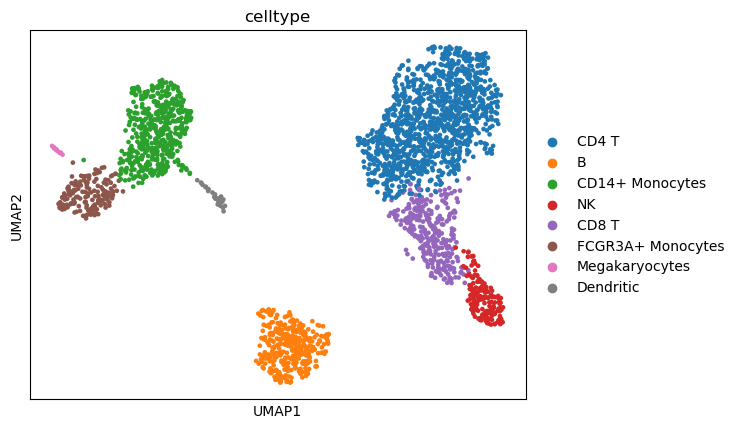

In [15]:
sc.pl.umap(adata, color="celltype")

In [16]:
np.random.seed(42)
n_cells = int(adata.n_obs * 0.35)
selected_idx = np.random.choice(adata.n_obs, n_cells, replace=False)
adata.obs['str_batch'] = '0'
batch_1_cells = adata.obs_names[selected_idx]
adata.obs.loc[batch_1_cells, 'str_batch'] = '1'


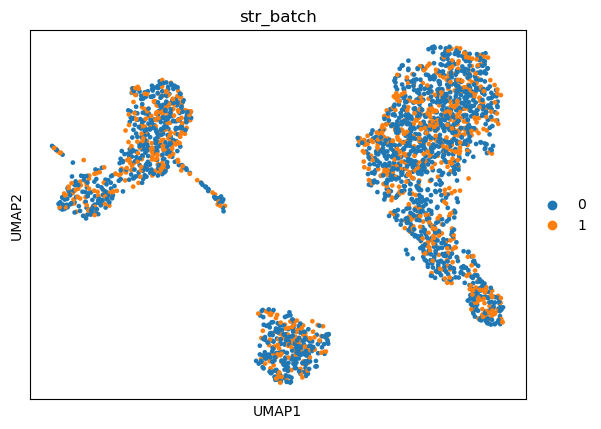

In [17]:
sc.pl.umap(adata, color="str_batch")

In [18]:
adata.write_h5ad(experiment/'data/pbmc3k_scanpy_annotated_batches.h5ad')